Delivered orders: 96,470
Late rate: 8.1%
Average delivery time (days): 12.6
Average review - on time: 4.29 | late: 2.57
Unhappy rate - on time: 9.2% | late: 54.0%
Total revenue: 13,220,249 | Revenue at risk: 639,252 (4.8%)


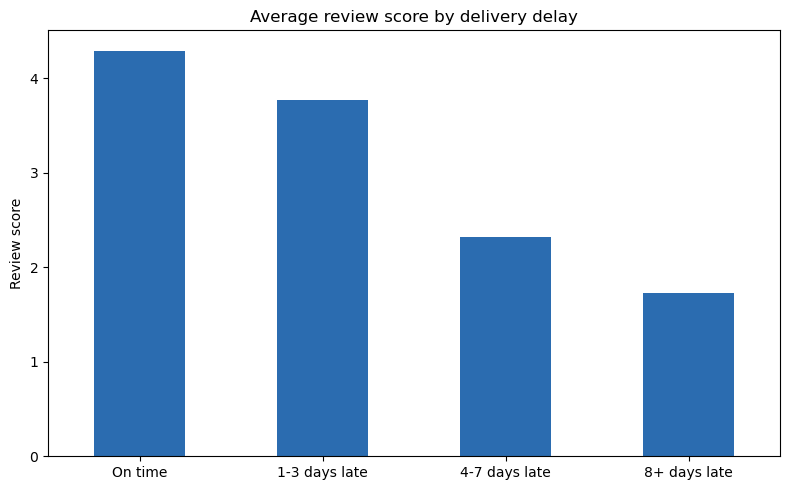

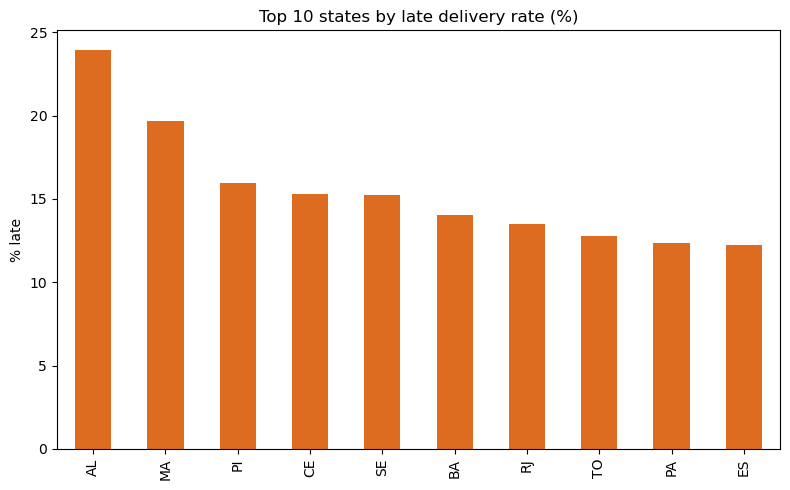

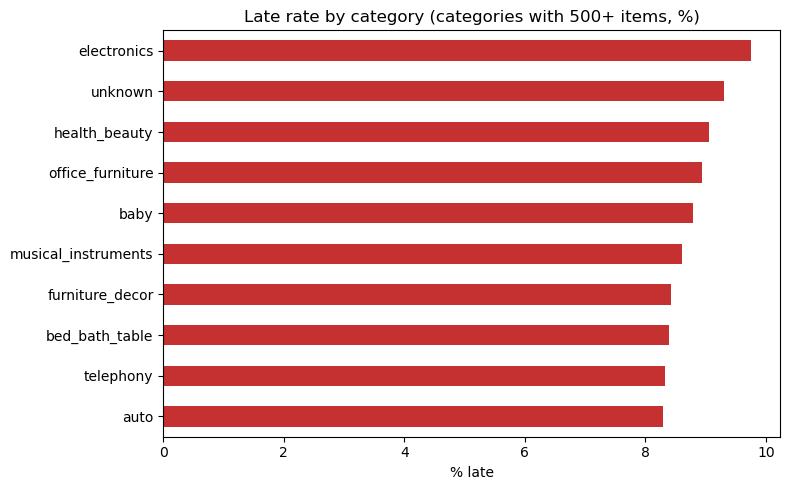

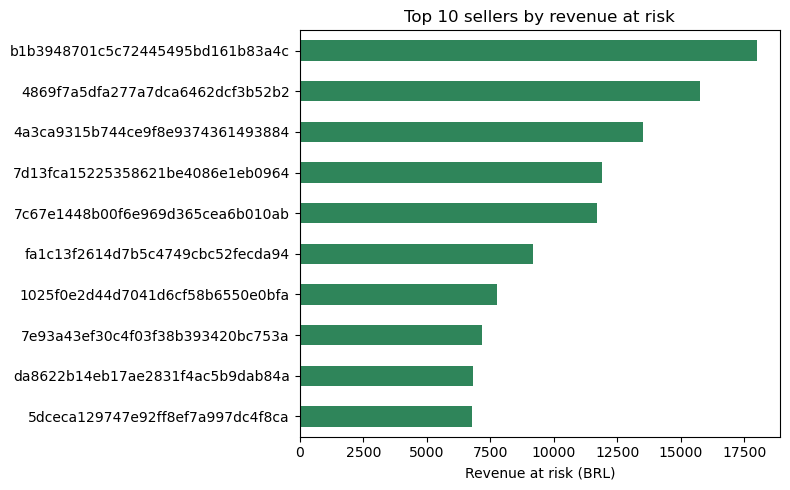

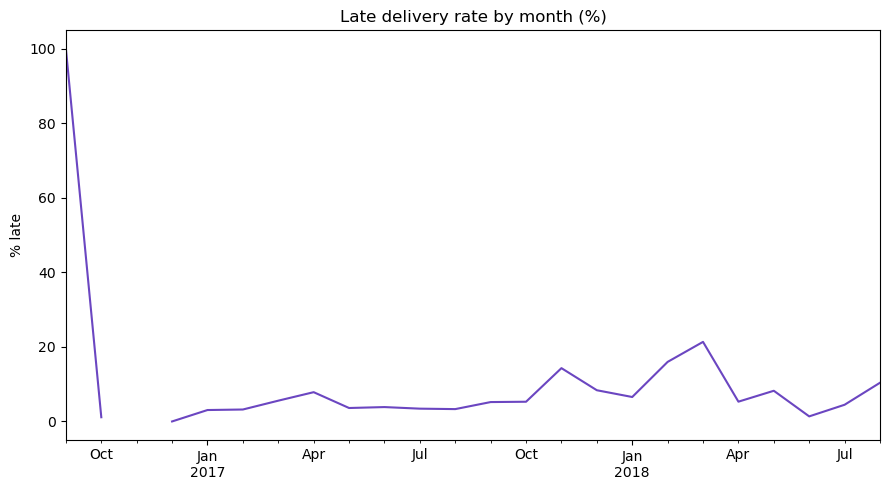

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("../outputs", exist_ok=True)
d = "../data/"

# 1. Open the files
orders = pd.read_csv(d + "olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"])
items = pd.read_csv(d + "olist_order_items_dataset.csv")
reviews = pd.read_csv(d + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(d + "olist_customers_dataset.csv")
products = pd.read_csv(d + "olist_products_dataset.csv")
trans = pd.read_csv(d + "product_category_name_translation.csv")

# 2. Keep delivered orders and calculate delivery KPIs
df = orders[(orders.order_status == "delivered") & orders.order_delivered_customer_date.notna()].copy()
df["delivery_days"] = (df.order_delivered_customer_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df["delay_days"] = (df.order_delivered_customer_date - df.order_estimated_delivery_date).dt.total_seconds() / 86400
df["late"] = df.delay_days > 0
df["bucket"] = pd.cut(df.delay_days, [-float("inf"), 0, 3, 7, float("inf")],
                      labels=["On time", "1-3 days late", "4-7 days late", "8+ days late"])

# 3. Join reviews, revenue and customer state
score = reviews.groupby("order_id").review_score.mean().reset_index()
revenue = items.groupby("order_id").price.sum().reset_index().rename(columns={"price": "revenue"})
df = df.merge(score, on="order_id", how="left").merge(revenue, on="order_id", how="left")
df = df.merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
df["unhappy"] = df.review_score <= 2
rev = df.dropna(subset=["review_score"])

# 4. Item level table (for sellers and categories)
products = products.merge(trans, on="product_category_name", how="left")
products["category"] = products.product_category_name_english.fillna("unknown")
it = items.merge(df[["order_id", "late", "unhappy"]], on="order_id") \
          .merge(products[["product_id", "category"]], on="product_id", how="left")
it["risk"] = it.price.where(it.late & it.unhappy, 0)

# 5. Key numbers
at_risk = df.revenue.where(df.late & df.unhappy, 0).sum()
print("Delivered orders:", f"{len(df):,}")
print("Late rate:", f"{df.late.mean():.1%}")
print("Average delivery time (days):", round(df.delivery_days.mean(), 1))
print("Average review - on time:", round(rev[~rev.late].review_score.mean(), 2),
      "| late:", round(rev[rev.late].review_score.mean(), 2))
print("Unhappy rate - on time:", f"{rev[~rev.late].unhappy.mean():.1%}",
      "| late:", f"{rev[rev.late].unhappy.mean():.1%}")
print("Total revenue:", f"{df.revenue.sum():,.0f}", "| Revenue at risk:", f"{at_risk:,.0f}",
      f"({at_risk / df.revenue.sum():.1%})")

# 6. Charts
def show(fig_name):
    plt.tight_layout()
    plt.savefig("../outputs/" + fig_name, dpi=150)
    plt.show()

rev.groupby("bucket", observed=True).review_score.mean().plot(kind="bar", figsize=(8, 5), color="#2b6cb0")
plt.title("Average review score by delivery delay"); plt.ylabel("Review score"); plt.xlabel("")
plt.xticks(rotation=0); show("1_review_by_delay.png")

(df.groupby("customer_state").late.mean().sort_values(ascending=False).head(10) * 100) \
    .plot(kind="bar", figsize=(8, 5), color="#dd6b20")
plt.title("Top 10 states by late delivery rate (%)"); plt.ylabel("% late"); plt.xlabel("")
show("2_late_by_state.png")

cat = it.groupby("category").agg(items=("price", "size"), late_rate=("late", "mean"))
(cat[cat["items"] >= 500].late_rate.sort_values(ascending=False).head(10) * 100) \
    .plot(kind="barh", figsize=(8, 5), color="#c53030")
plt.title("Late rate by category (categories with 500+ items, %)"); plt.xlabel("% late"); plt.ylabel("")
plt.gca().invert_yaxis(); show("3_late_by_category.png")

it.groupby("seller_id").risk.sum().sort_values(ascending=False).head(10) \
    .plot(kind="barh", figsize=(8, 5), color="#2f855a")
plt.title("Top 10 sellers by revenue at risk"); plt.xlabel("Revenue at risk (BRL)"); plt.ylabel("")
plt.gca().invert_yaxis(); show("4_sellers_at_risk.png")

df.set_index("order_purchase_timestamp").late.resample("ME").mean().mul(100) \
    .plot(figsize=(9, 5), color="#6b46c1")
plt.title("Late delivery rate by month (%)"); plt.ylabel("% late"); plt.xlabel("")
show("5_late_by_month.png")

In [2]:
print("TOP 5 STATES BY LATE RATE (%)")
print((df.groupby("customer_state").late.mean().sort_values(ascending=False).head(5) * 100).round(1))

print("\nTOP 5 CATEGORIES BY LATE RATE (%) - 500+ items")
print((cat[cat["items"] >= 500].late_rate.sort_values(ascending=False).head(5) * 100).round(1))

print("\nTOP 5 SELLERS BY REVENUE AT RISK")
print(it.groupby("seller_id").risk.sum().sort_values(ascending=False).head(5).round(0))

print("\nREVIEW SCORE BY DELAY GROUP")
print(rev.groupby("bucket", observed=True).review_score.mean().round(2))

TOP 5 STATES BY LATE RATE (%)
customer_state
AL    23.9
MA    19.7
PI    16.0
CE    15.3
SE    15.2
Name: late, dtype: float64

TOP 5 CATEGORIES BY LATE RATE (%) - 500+ items
category
electronics         9.7
unknown             9.3
health_beauty       9.1
office_furniture    8.9
baby                8.8
Name: late_rate, dtype: float64

TOP 5 SELLERS BY REVENUE AT RISK
seller_id
b1b3948701c5c72445495bd161b83a4c    18000.0
4869f7a5dfa277a7dca6462dcf3b52b2    15743.0
4a3ca9315b744ce9f8e9374361493884    13500.0
7d13fca15225358621be4086e1eb0964    11882.0
7c67e1448b00f6e969d365cea6b010ab    11717.0
Name: risk, dtype: float64

REVIEW SCORE BY DELAY GROUP
bucket
On time          4.29
1-3 days late    3.77
4-7 days late    2.32
8+ days late     1.73
Name: review_score, dtype: float64


In [3]:
sellers = pd.read_csv(d + "olist_sellers_dataset.csv")
x = items.merge(sellers[["seller_id", "seller_state"]], on="seller_id") \
         .merge(df[["order_id", "customer_state", "late"]], on="order_id")
x["same_state"] = x.seller_state == x.customer_state

print("LATE RATE (%) - seller and customer in the SAME state or not")
print((x.groupby("same_state").late.mean() * 100).round(1))

print("\nWHERE SELLERS ARE (% of items sold)")
print((x.seller_state.value_counts(normalize=True).head(3) * 100).round(0))

LATE RATE (%) - seller and customer in the SAME state or not
same_state
False    9.0
True     6.0
Name: late, dtype: float64

WHERE SELLERS ARE (% of items sold)
seller_state
SP    71.0
MG     8.0
PR     8.0
Name: proportion, dtype: float64


In [4]:
df["promised_days"] = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
ne = ["AL", "MA", "PI", "CE", "SE"]
df["group"] = df.customer_state.isin(ne).map({True: "North-east 5 states", False: "All other states"})

print("AVERAGE DAYS: promised vs real delivery")
print(df.groupby("group")[["promised_days", "delivery_days"]].mean().round(1))

print("\nLATE RATE (%)")
print((df.groupby("group").late.mean() * 100).round(1))

AVERAGE DAYS: promised vs real delivery
                     promised_days  delivery_days
group                                            
All other states              23.5           12.3
North-east 5 states           31.1           21.5

LATE RATE (%)
group
All other states        7.8
North-east 5 states    17.4
Name: late, dtype: float64


In [5]:
target = df[df.delay_days > 3]
n_orders = len(target)
target_revenue = target.revenue.sum()
risk = target.revenue.where(target.unhappy, 0).sum()
voucher_rate = 0.10
cost = target_revenue * voucher_rate

print("Orders more than 3 days late:", f"{n_orders:,}")
print("Their total revenue:", f"{target_revenue:,.0f}")
print("Revenue at risk among them:", f"{risk:,.0f}")
print("Voucher cost (10% of their revenue):", f"{cost:,.0f}")
print()

for name, recover in [("Worst case", 0.10), ("Normal case", 0.25), ("Best case", 0.40)]:
    saved = risk * recover
    print(f"{name}: recover {recover:.0%} of at-risk revenue -> saved {saved:,.0f}, net gain {saved - cost:,.0f}")

Orders more than 3 days late: 5,164
Their total revenue: 799,559
Revenue at risk among them: 574,359
Voucher cost (10% of their revenue): 79,956

Worst case: recover 10% of at-risk revenue -> saved 57,436, net gain -22,520
Normal case: recover 25% of at-risk revenue -> saved 143,590, net gain 63,634
Best case: recover 40% of at-risk revenue -> saved 229,744, net gain 149,788


In [6]:
import base64, io, webbrowser

def img(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

charts = []

fig, ax = plt.subplots(figsize=(6, 4))
rev.groupby("bucket", observed=True).review_score.mean().plot(kind="bar", ax=ax, color="#2b6cb0")
ax.set_title("Average review score by delivery delay"); ax.set_xlabel(""); ax.set_ylabel("Review score")
plt.setp(ax.get_xticklabels(), rotation=0)
charts.append(img(fig))

fig, ax = plt.subplots(figsize=(6, 4))
(df.groupby("customer_state").late.mean().sort_values(ascending=False).head(10) * 100).plot(kind="bar", ax=ax, color="#dd6b20")
ax.set_title("Top 10 states by late rate (%)"); ax.set_xlabel(""); ax.set_ylabel("% late")
charts.append(img(fig))

fig, ax = plt.subplots(figsize=(6, 4))
(cat[cat["items"] >= 500].late_rate.sort_values(ascending=False).head(10) * 100).plot(kind="barh", ax=ax, color="#c53030")
ax.set_title("Late rate by category (500+ items, %)"); ax.set_ylabel(""); ax.set_xlabel("% late"); ax.invert_yaxis()
charts.append(img(fig))

s = it.groupby("seller_id").risk.sum().sort_values(ascending=False).head(10)
s.index = [i[:6] for i in s.index]
fig, ax = plt.subplots(figsize=(6, 4))
s.plot(kind="barh", ax=ax, color="#2f855a")
ax.set_title("Top 10 sellers by revenue at risk"); ax.set_ylabel(""); ax.set_xlabel("Revenue at risk (BRL)"); ax.invert_yaxis()
charts.append(img(fig))

fig, ax = plt.subplots(figsize=(6, 4))
df.set_index("order_purchase_timestamp").late.resample("ME").mean().mul(100).plot(ax=ax, color="#6b46c1")
ax.set_title("Late rate by month (%)"); ax.set_xlabel(""); ax.set_ylabel("% late")
charts.append(img(fig))

cases = {"Worst": 0.10, "Normal": 0.25, "Best": 0.40}
net = [risk * r - cost for r in cases.values()]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(list(cases.keys()), net, color=["#c53030" if v < 0 else "#2f855a" for v in net])
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Voucher plan: net gain by scenario (BRL)")
charts.append(img(fig))

kpis = [
    ("Delivered orders", f"{len(df):,}"),
    ("Late rate", f"{df.late.mean():.1%}"),
    ("Average delivery time", f"{df.delivery_days.mean():.1f} days"),
    ("Review score: on time vs late", f"{rev[~rev.late].review_score.mean():.2f} vs {rev[rev.late].review_score.mean():.2f}"),
    ("Unhappy rate: on time vs late", f"{rev[~rev.late].unhappy.mean():.1%} vs {rev[rev.late].unhappy.mean():.1%}"),
    ("Revenue at risk", f"{at_risk:,.0f} ({at_risk / df.revenue.sum():.1%})"),
]
cards = "".join(f'<div class="card"><div class="label">{a}</div><div class="value">{b}</div></div>' for a, b in kpis)
pics = "".join(f'<div class="chart"><img src="{c}"></div>' for c in charts)

template = """
<html><head><meta charset="utf-8"><title>Olist Late Delivery Dashboard</title>
<style>
body { font-family: Arial, sans-serif; background: #f4f6f8; margin: 0; padding: 24px; color: #1a202c; }
h1 { margin: 0 0 4px 0; } .sub { color: #4a5568; margin-bottom: 20px; }
.cards { display: grid; grid-template-columns: repeat(3, 1fr); gap: 12px; margin-bottom: 20px; }
.card { background: white; border-radius: 8px; padding: 14px; box-shadow: 0 1px 3px rgba(0,0,0,0.1); }
.label { font-size: 13px; color: #4a5568; } .value { font-size: 24px; font-weight: bold; margin-top: 4px; }
.charts { display: grid; grid-template-columns: repeat(2, 1fr); gap: 12px; margin-bottom: 20px; }
.chart { background: white; border-radius: 8px; padding: 10px; box-shadow: 0 1px 3px rgba(0,0,0,0.1); }
.chart img { width: 100%; }
.box { background: white; border-radius: 8px; padding: 16px; margin-bottom: 12px; box-shadow: 0 1px 3px rgba(0,0,0,0.1); }
</style></head><body>
<h1>Olist Late Delivery Early-Warning Dashboard</h1>
<div class="sub">Operations and Marketing view | Data: Olist public dataset, 2016-2018</div>
<div class="cards">__CARDS__</div>
<div class="charts">__CHARTS__</div>
<div class="box"><b>Operations should:</b>
<ul><li>Focus on the five north-east states (AL, MA, PI, CE, SE), where up to 1 in 4 orders is late.</li>
<li>Track orders still in transit after their expected date, and investigate the slowest 10% of orders.</li>
<li>Put the top sellers by revenue at risk on a watch list.</li>
<li>Target: no order more than 3 days late. About 5,000 orders above that line carry about 90% of revenue at risk.</li></ul></div>
<div class="box"><b>Marketing should:</b>
<ul><li>Send an apology message and a small voucher to customers whose order will be more than 3 days late.</li>
<li>Test first: send it to half of the late orders, compare reviews and repeat purchases after 1 to 2 months.</li>
<li>The plan breaks even if it recovers about 14% of at-risk revenue.</li></ul></div>
<div class="box"><b>Limits:</b> Revenue at risk is not proven lost money. Recovery rates and voucher cost are assumptions. The data is old, and most customers buy only once.</div>
</body></html>
"""
html = template.replace("__CARDS__", cards).replace("__CHARTS__", pics)

with open("../outputs/dashboard.html", "w") as f:
    f.write(html)

webbrowser.open("file://" + os.path.abspath("../outputs/dashboard.html"))
print("Dashboard saved in the outputs folder")

Dashboard saved in the outputs folder


In [7]:
first_cat = it.drop_duplicates("order_id")[["order_id", "category"]]
c = rev.merge(first_cat, on="order_id")

g = c.groupby(["category", "late"]).unhappy.mean().unstack() * 100
g["orders"] = c.groupby("category").size()
g = g[g.orders >= 500].round(1)
g.columns = ["on_time_unhappy_%", "late_unhappy_%", "orders"]

print(g.sort_values("orders", ascending=False).head(10))
print()
print("Categories where late orders are unhappier:",
      (g["late_unhappy_%"] > g["on_time_unhappy_%"]).sum(), "of", len(g))

                       on_time_unhappy_%  late_unhappy_%  orders
category                                                        
bed_bath_table                      11.8            55.8    9072
health_beauty                        7.3            52.2    8562
sports_leisure                       7.5            56.2    7446
computers_accessories               11.2            53.5    6469
furniture_decor                     11.3            54.3    6167
housewares                           8.7            50.1    5655
watches_gifts                        9.5            56.8    5430
telephony                           10.8            48.3    4052
auto                                 9.1            52.6    3774
toys                                 7.5            59.0    3748

Categories where late orders are unhappier: 26 of 26


In [8]:
cols = ["order_id", "order_purchase_timestamp", "customer_state", "delivery_days",
        "delay_days", "late", "bucket", "review_score", "revenue"]
o = df[cols].copy()
o["late"] = o.late.astype(int)
o["unhappy"] = (o.review_score <= 2).astype(float).where(o.review_score.notna())
o.to_csv("../outputs/powerbi_orders.csv", index=False)

p = it[["order_id", "seller_id", "category", "price", "late", "risk"]].copy()
p["late"] = p.late.astype(int)
p.to_csv("../outputs/powerbi_items.csv", index=False)

print("Saved:", len(o), "orders and", len(p), "items")

Saved: 96470 orders and 110189 items
